In [14]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [15]:
image = cv2.imread('sar_2.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

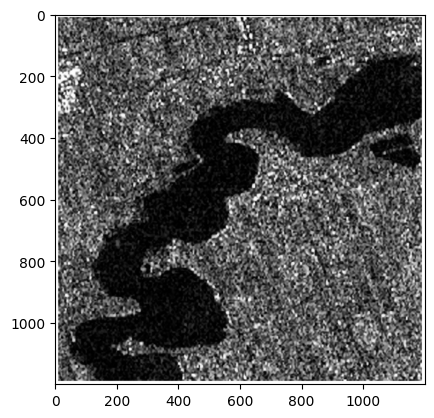

In [16]:
plt.imshow(image_gray, cmap="gray")

# Точечная бинаризация

In [17]:
import copy

bin_img = copy.deepcopy(image_gray)
T  = 50
bin_img[image_gray < T] = 0
bin_img[image_gray >= T] = 255

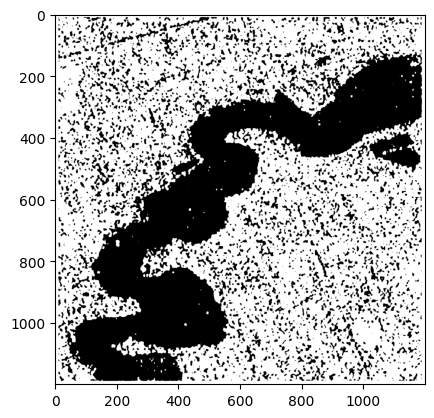

In [18]:
plt.imshow(bin_img, cmap="gray")

# Бинаризация Отсу

In [19]:
# otsu binarization
_,th2 = cv2.threshold(image_gray,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)

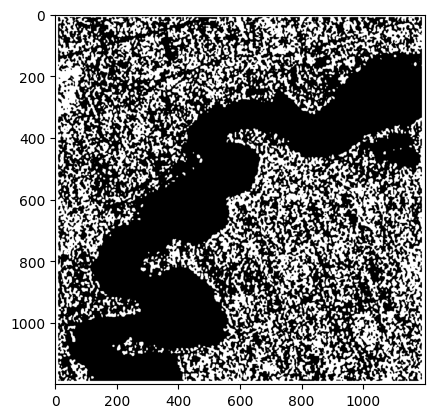

In [20]:
plt.imshow(th2, cmap="gray")

# Адаптивная бинаризация

In [21]:
#
th3 = cv2.adaptiveThreshold(image_gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,71,21)


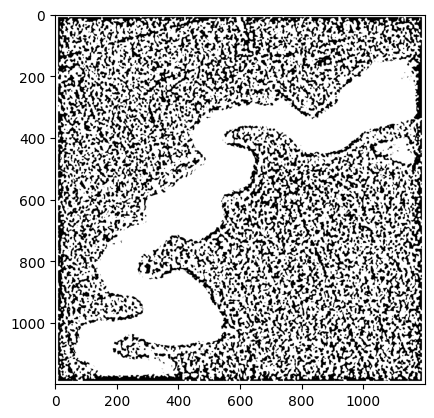

In [22]:
plt.imshow(th3, cmap="gray")

# Оператор Собеля

In [23]:
scale = 1
delta = 0
ddepth = cv2.CV_16S
grad_x = cv2.Sobel(image_gray, ddepth, 1, 0, ksize=3, scale=scale, delta=delta, borderType=cv2.BORDER_DEFAULT)
grad_y = cv2.Sobel(image_gray, ddepth, 0, 1, ksize=3, scale=scale, delta=delta, borderType=cv2.BORDER_DEFAULT)

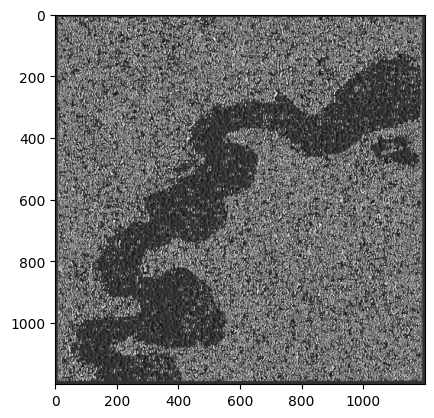

In [24]:
plt.imshow((grad_x - grad_x.min())*255, cmap="gray")

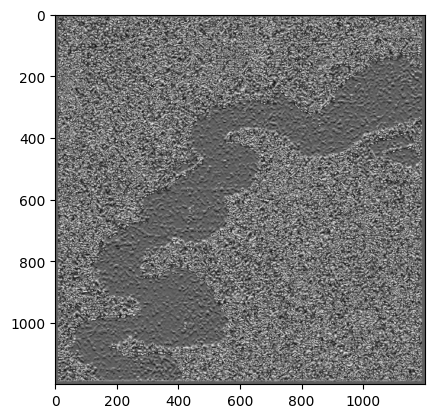

In [25]:
plt.imshow((grad_y - grad_y.min())*255, cmap="gray")

In [26]:
grad = cv2.addWeighted(grad_x, 0.5, grad_y, 0.5,0.0) # mean value between

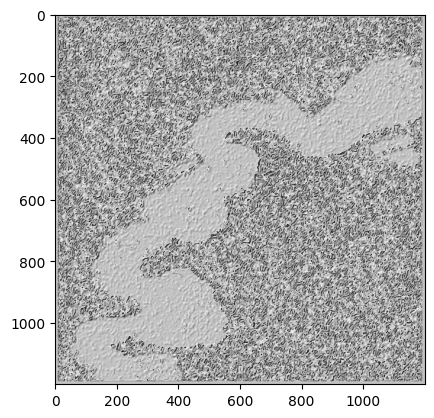

In [27]:
plt.imshow((grad - grad.min())*255, cmap="gray")

# Canny

In [28]:
edges = cv2.Canny(image_gray,100,200)

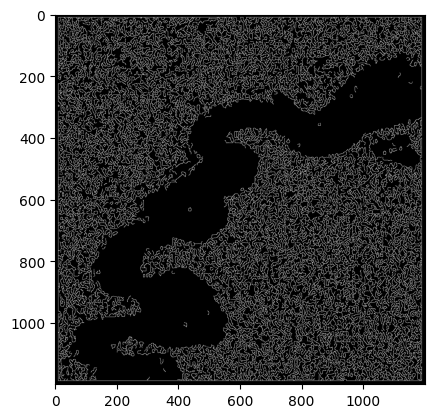

In [29]:
plt.imshow(edges, cmap="gray")

# Преобразование Хафа

In [30]:
image = cv2.imread('img_1.jpg')
image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

error: OpenCV(4.14.0) /io/opencv/modules/imgproc/src/color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'


In [ ]:
plt.imshow(image)

In [ ]:
canny = cv2.Canny(image_gray,50,150,apertureSize = 3)

In [ ]:
lines = cv2.HoughLines(canny, 1, np.pi / 180, 190)

In [ ]:
import math

if lines is not None:
        for i in range(0, len(lines)):
            rho = lines[i][0][0]
            theta = lines[i][0][1]
            a = math.cos(theta)
            b = math.sin(theta)
            x0 = a * rho
            y0 = b * rho
            pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
            pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
            cv2.line(image, pt1, pt2, (0,0,255), 3, cv2.LINE_AA)

In [ ]:
plt.imshow(image)

In [ ]:
#ДЗ
# 1. Для изображения sar_3.jpg найти наиболее протяженный участок
# (выделить линии при помощи преобразования Хафа)
# 2. Для изображения sar_3.jpg провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.

# ДЗ 1. Преобразование Хафа, sar_3.jpg

In [31]:
image = cv2.imread('sar_3.jpg')
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

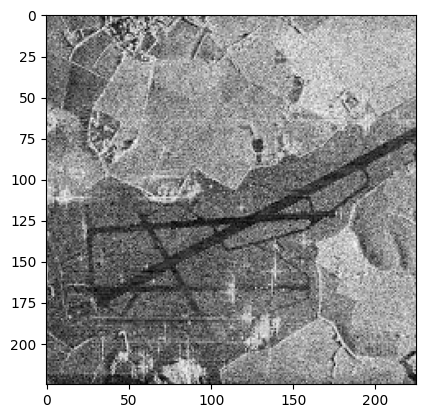

In [32]:
plt.imshow(image_gray, cmap="gray")

In [33]:
image_blur = cv2.GaussianBlur(image_gray, (5,5), 0)
image_inv = np.where(image_blur >= 65, 0, 255).astype(np.uint8)
image_open = cv2.morphologyEx(image_inv, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))
image_close = cv2.morphologyEx(image_open, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9,9)))
canny = cv2.Canny(image_close, 50, 150)

In [34]:
lines = cv2.HoughLinesP(canny, 1, np.pi / 180, 40, minLineLength = 80, maxLineGap = 30).reshape(-1, 4)

In [35]:
import math

image_lines = image_rgb.copy()
max_len = 0
for x1, y1, x2, y2 in lines:
    cv2.line(image_lines, (x1, y1), (x2, y2), (0,255,0), 1, cv2.LINE_AA)
    length = math.hypot(x2 - x1, y2 - y1)
    if length > max_len:
        max_len = length
        longest = (x1, y1, x2, y2)

cv2.line(image_lines, longest[:2], longest[2:], (255,0,0), 3, cv2.LINE_AA)
print(len(lines), longest, max_len)

4 (np.int32(33), np.int32(177), np.int32(207), np.int32(84)) 197.29419656948858


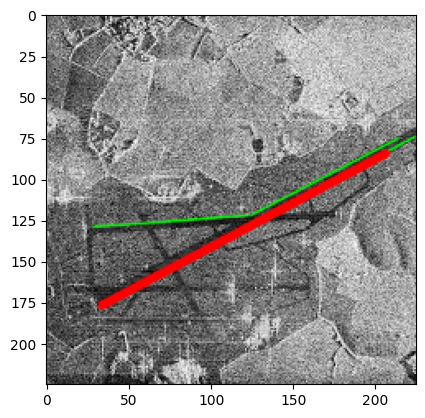

In [36]:
plt.imshow(image_lines)

# ДЗ 2. Бинаризация, sar_3.jpg

In [37]:
image_blur = cv2.GaussianBlur(image_gray, (5,5), 0)

image_bin_t65 = np.where(image_blur >= 65, 255, 0).astype(np.uint8)
image_bin_t90 = np.where(image_blur >= 90, 255, 0).astype(np.uint8)
t_otsu, image_bin_otsu = cv2.threshold(image_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
image_bin_gauss = cv2.adaptiveThreshold(image_blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 71, 21)
image_bin_mean = cv2.adaptiveThreshold(image_blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 51, 10)
print(t_otsu)

128.0


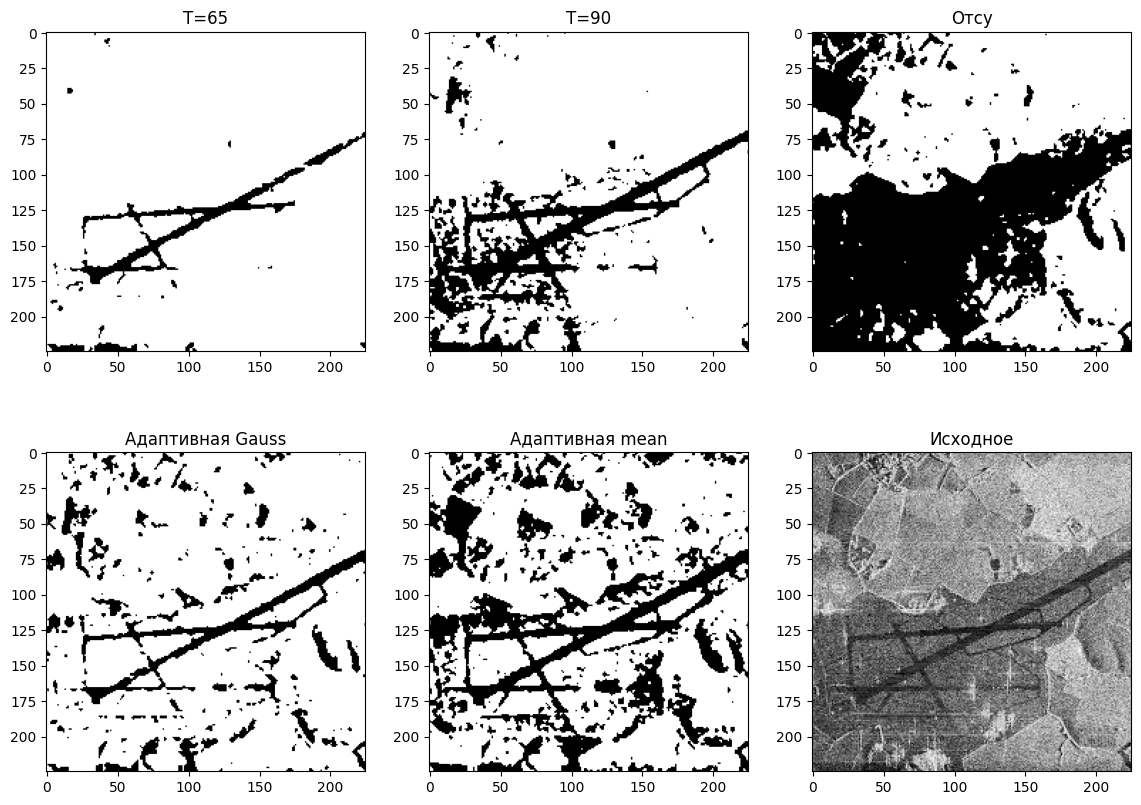

In [38]:
fig, ax = plt.subplots(2, 3, figsize=(14, 10))
ax[0,0].imshow(image_bin_t65, cmap="gray"); ax[0,0].set_title('T=65')
ax[0,1].imshow(image_bin_t90, cmap="gray"); ax[0,1].set_title('T=90')
ax[0,2].imshow(image_bin_otsu, cmap="gray"); ax[0,2].set_title('Отсу')
ax[1,0].imshow(image_bin_gauss, cmap="gray"); ax[1,0].set_title('Адаптивная Gauss')
ax[1,1].imshow(image_bin_mean, cmap="gray"); ax[1,1].set_title('Адаптивная mean')
ax[1,2].imshow(image_gray, cmap="gray"); ax[1,2].set_title('Исходное')
plt.show()

## Выделение полосы

In [39]:
image_inv = cv2.bitwise_not(image_bin_t65)
image_open = cv2.morphologyEx(image_inv, cv2.MORPH_OPEN, np.ones((3,3), np.uint8))
image_close = cv2.morphologyEx(image_open, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9,9)))

array([[[116, 116, 116],
        [ 59,  59,  59],
        [128, 128, 128],
        ...,
        [187, 187, 187],
        [192, 192, 192],
        [195, 195, 195]],

       [[143, 143, 143],
        [114, 114, 114],
        [ 93,  93,  93],
        ...,
        [198, 198, 198],
        [147, 147, 147],
        [209, 209, 209]],

       [[104, 104, 104],
        [ 96,  96,  96],
        [119, 119, 119],
        ...,
        [169, 169, 169],
        [191, 191, 191],
        [188, 188, 188]],

       ...,

       [[117, 117, 117],
        [ 59,  59,  59],
        [ 85,  85,  85],
        ...,
        [101, 101, 101],
        [ 20,  20,  20],
        [ 23,  23,  23]],

       [[ 88,  88,  88],
        [149, 149, 149],
        [ 64,  64,  64],
        ...,
        [158, 158, 158],
        [102, 102, 102],
        [ 50,  50,  50]],

       [[ 61,  61,  61],
        [110, 110, 110],
        [102, 102, 102],
        ...,
        [146, 146, 146],
        [124, 124, 124],
        [ 53,  53,  53]]], dtype=uint8)
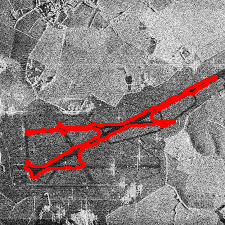

In [40]:
num, labels, stats, centroids = cv2.connectedComponentsWithStats(image_close)
runway = np.argmax(stats[1:, cv2.CC_STAT_AREA]) + 1
mask = np.where(labels == runway, 255, 0).astype(np.uint8)

contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
image_runway = image_rgb.copy()
cv2.drawContours(image_runway, contours, -1, (255,0,0), 2)

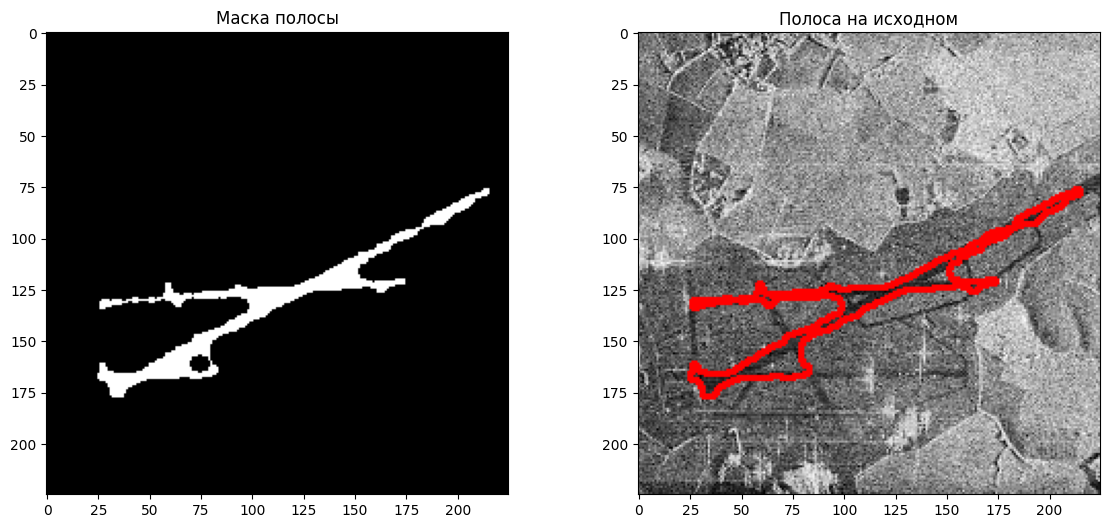

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(mask, cmap="gray"); ax[0].set_title('Маска полосы')
ax[1].imshow(image_runway); ax[1].set_title('Полоса на исходном')
plt.show()

**Вывод 1.** Самый протяженный участок - ось взлетной полосы вдоль всей ее длины около 197 px

**Вывод 2.** Лучший результат дал глобальный порог T=65 на сглаженном изображении: полоса темная, и она отделяется от остального